In [25]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [41]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr

from src.utils.cdo_commands import cdo_remap
from src.utils.utils_xarray import sel_extent
from src.utils.constants import EXTENT_BC, EXTENT_BC_MRRO, EXTENT_CH

In [42]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])

# CERRA

In [4]:
ds_2t_cerra = xr.open_zarr("/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/2t.zarr", chunks="auto")

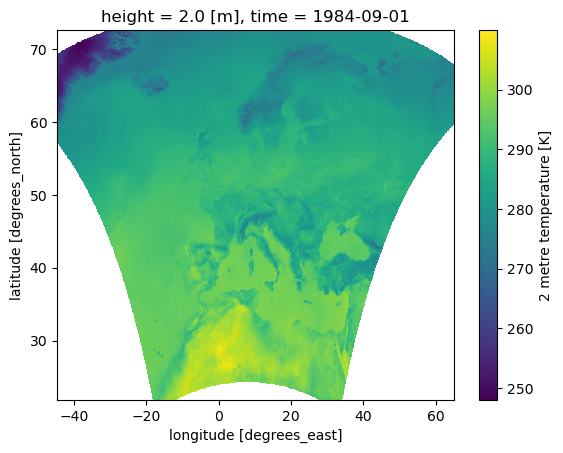

In [8]:
ds_2t_cerra["2t"].isel(time=0).plot()

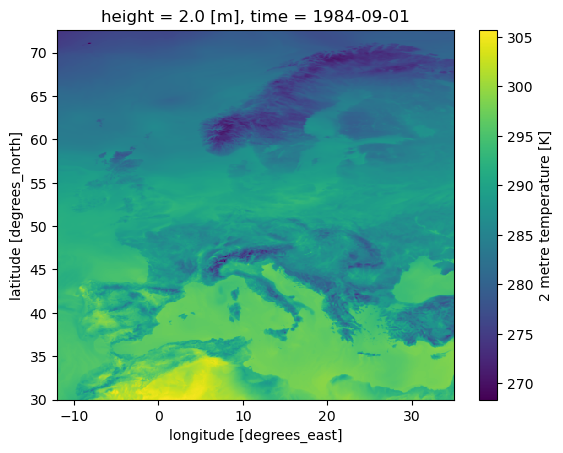

In [12]:
sel_extent(ds_2t_cerra["2t"].isel(time=0), extent=EXTENT_BC).plot()

# CNRM

In [13]:
path_tas_cnrm = Path("/net/atmos/data/cordex/EUR-11/rcp85/3hr/tas/CNRM/CNRM-CERFACS-CNRM-CM5/CNRM-ALADIN63/r1i1p1/")
ds_tas_cnrm = xr.open_dataset(sorted(path_tas_cnrm.glob("*.nc"))[0], chunks="auto")

In [ ]:
cdo_remap(
    str(sorted(path_tas_cnrm.glob("*.nc"))[0]),
    str(Path.cwd() / sorted(path_tas_cnrm.glob("*.nc"))[0].name),
    "conservative",
    path_data_processed / "climate_grids" / climate_grid_file,
)

In [14]:
ds_tas_cnrm_regridded = xr.open_zarr("/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/regridded/3hr/tas.zarr", chunks="auto").sel(time="2006")
ds_tas_cnrm_regridded

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 2920, lat: 507, lon: 1096)
Coordinates:
    height   (time) float64 23kB dask.array<chunksize=(2920,), meta=np.ndarray>
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * time     (time) datetime64[ns] 23kB 2006-01-01 ... 2006-12-31T21:00:00
Data variables:
    tas      (time, lat, lon) float32 6GB dask.array<chunksize=(2920, 20, 20), meta=np.ndarray>
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

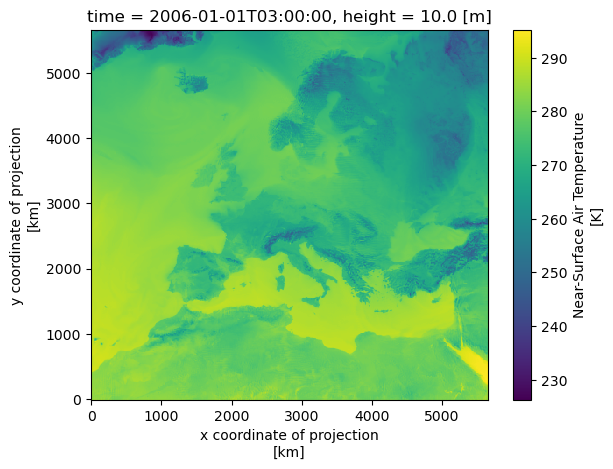

In [15]:
ds_tas_cnrm.tas.isel(time=0).plot()

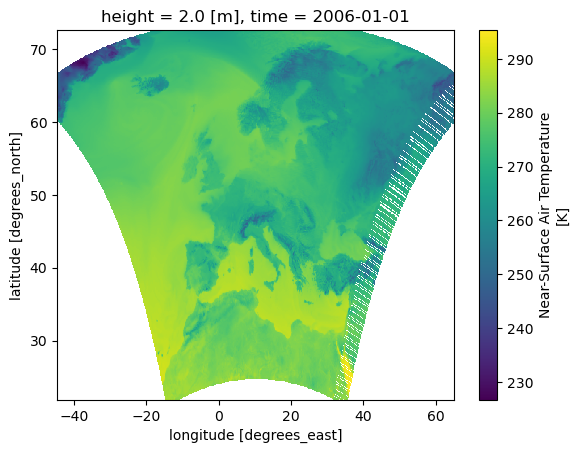

In [16]:
ds_tas_cnrm_regridded.tas.isel(time=0).plot()

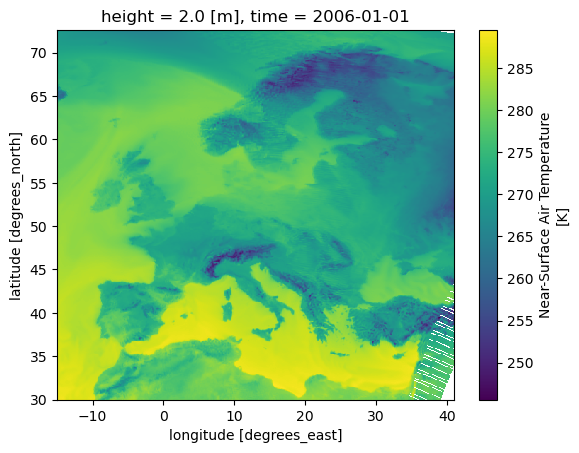

In [39]:
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).plot()

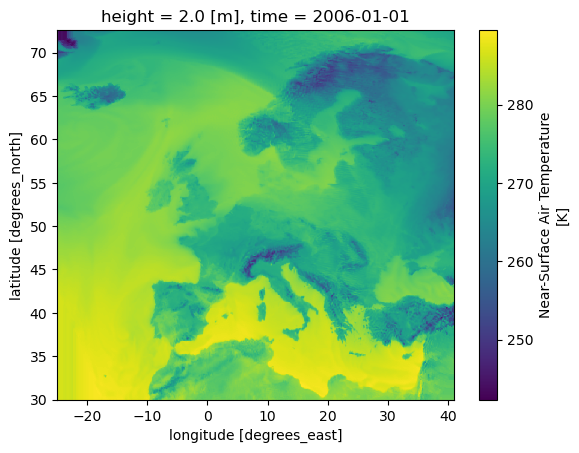

In [35]:
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).ffill(dim="lat").ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot()

# MOHC

In [18]:
path_tas_mohc = Path("/net/atmos/data/cordex/EUR-11/rcp85/3hr/tas/MOHC/CNRM-CERFACS-CNRM-CM5/MOHC-HadREM3-GA7-05/r1i1p1/")
ds_tas_mohc = xr.open_dataset(sorted(path_tas_mohc.glob("*.nc"))[0], chunks="auto")

In [19]:
ds_tas_mohc_regridded = xr.open_zarr("/landclim/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/regridded/3hr/tas.zarr", chunks="auto").sel(time="2006")
ds_tas_mohc_regridded

<xarray.Dataset> Size: 6GB
Dimensions:  (lat: 507, lon: 1096, time: 2920)
Coordinates:
    height   float64 8B ...
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * time     (time) datetime64[ns] 23kB 2006-01-01 ... 2006-12-31T21:00:00
Data variables:
    tas      (time, lat, lon) float32 6GB dask.array<chunksize=(2920, 20, 20), meta=np.ndarray>
Attributes: (12/25)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.4
    c3s_disclaimer:                 This data has been produced in the contex...
    contact:                        erasmo.buonomo@metoffice.gov.uk
    ...                             ...
    model_id:                       MOHC-HadREM3-GA7-05
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     https://www.metoffice.gov.uk/climate-guid...
    tracking_id:                    hdl:21.14103/2067855c-322a-44b3-9e5b-d75d...

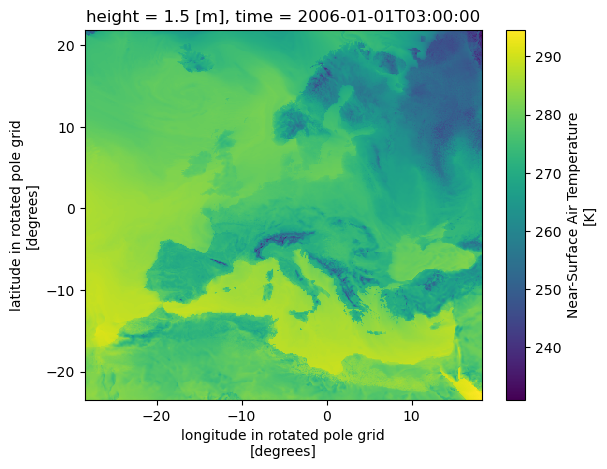

In [20]:
ds_tas_mohc.tas.isel(time=0).plot()

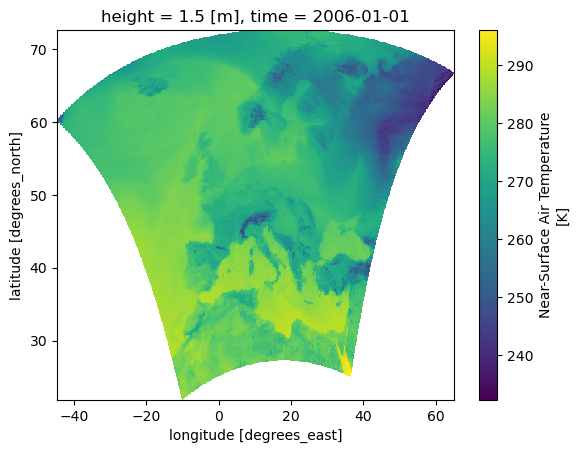

In [21]:
ds_tas_mohc_regridded.tas.isel(time=0).plot()

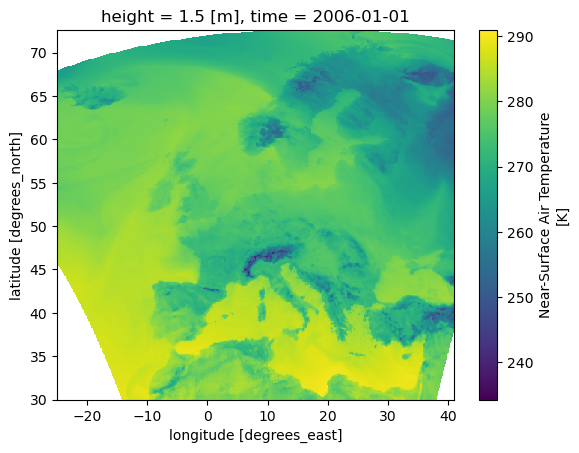

In [36]:
sel_extent(ds_tas_mohc_regridded.tas.isel(time=0), extent=EXTENT_BC).plot()

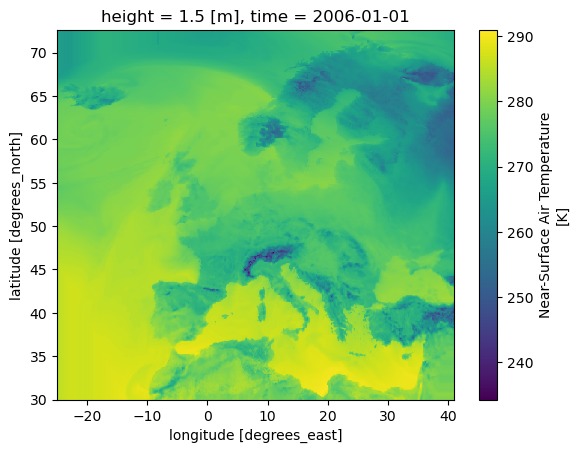

In [37]:
sel_extent(ds_tas_mohc_regridded.tas.isel(time=0), extent=EXTENT_BC).ffill(dim="lat").ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot()

# Timestep adjustment

In [28]:
pd.read_csv("/net/cfc/landclim1/sboersig/projects/GCM-Matching/Stitching/CodeCH2025/output/year_lists_tuned.csv")

,name,start_year,year_list,scenarios_mapped,mode
0,CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_r12i1p1_EC-Ea...,1991,"[1990, 1991, 1992, 1993, 1994, 1995, 1996, 199...",rcp85,tuning
1,CLMcom-CCLM4-8-17_MIROC-MIROC5_r1i1p1_MIROC-ES...,1994,"[1984, 1986, 1988, 1990, 1993, 1995, 1997, 199...",rcp85,tuning
2,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_CNR...,1992,"[1999, 2000, 2001, 2000, 2001, 2002, 2003, 200...",rcp26,tuning
3,DMI-HIRHAM5_ICHEC-EC-EARTH_r3i1p1_EC-Earth3_r9...,1991,"[1985, 1987, 1989, 1990, 1992, 1994, 1995, 199...",rcp26,tuning
4,DMI-HIRHAM5_MOHC-HadGEM2-ES_r1i1p1_HadGEM3-GC3...,1992,"[1985, 1987, 1988, 1990, 1992, 1994, 1996, 199...",rcp45,tuning
5,ICTP-RegCM4-6_MOHC-HadGEM2-ES_r1i1p1_HadGEM3-G...,1991,"[1994, 1995, 1996, 1997, 1998, 1999, 2000, 200...",rcp85,tuning
6,MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1_EC-...,1991,"[1985, 1987, 1988, 1990, 1991, 1993, 1994, 199...",rcp85,tuning
7,MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_UKE...,1991,"[1996, 1997, 1998, 1999, 2000, 2001, 2000, 200...",rcp85,tuning
8,MPI-CSC-REMO2009_MPI-M-MPI-ESM-LR_r1i1p1_MPI-E...,1997,"[1982, 1985, 1987, 1990, 1992, 1994, 1997, 199...",rcp26,tuning
9,MPI-CSC-REMO2009_MPI-M-MPI-ESM-LR_r2i1p1_MPI-E...,1994,"[1983, 1985, 1987, 1989, 1991, 1993, 1995, 199...",rcp45,tuning
